# Comparing models and temporal cross-validation

How to read the search result and compare models rigorously:

1. **Ranking of the finalists** on the selection layer (`V_select`).
2. **Temporal cross-validation** (rolling origin) with its own folds, to compare several models on the same origins.
3. **Statistical tests** (Wilcoxon and Diebold-Mariano with Holm; Friedman with the Nemenyi critical difference).
4. **Final comparison on the sealed test**, one evaluation per model.
5. **Nested cross-validation** of the whole procedure: how well the automatic selection generalizes.

Tables and tests serve the **report**: the champion is chosen by the protocol's rule, and the sealed test never goes back into the search.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## 1. Experiment and search

In [2]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily")
exp = AutoHybridExperiment(
    fh=14,
    session_id=42,
    progress=True,
    fold=3,
    base_models=["naive", "seasonal_naive", "linear", "knn", "mlp"],
    correctors=["linear", "knn"],
    residual_windows=[7],
).fit(y)
result = exp.compare_models()
result.best

busca S0 bases:   0%|          | 0/5 [00:00<?, ?cand/s]

busca S0 bases:  60%|██████    | 3/5 [00:02<00:01,  1.28cand/s]

busca S0 bases:  80%|████████  | 4/5 [00:02<00:00,  1.78cand/s]

busca S0 bases: 100%|██████████| 5/5 [00:03<00:00,  1.63cand/s]

busca S0 bases: 100%|██████████| 5/5 [00:03<00:00,  1.58cand/s]

...

seleção V_select:   0%|          | 0/5 [00:00<?, ?cand/s]

seleção V_select:  20%|██        | 1/5 [00:00<00:01,  2.40cand/s]

seleção V_select:  40%|████      | 2/5 [00:01<00:02,  1.18cand/s]

seleção V_select: 100%|██████████| 5/5 [00:01<00:00,  3.09cand/s]

CandidateSpec(family='residual', strategy='residual_additive', base=ModelSpec(name='mlp', params_json='{"lags":7}'), corrector=ModelSpec(name='linear', params_json='{}'), window_size=7, alpha=0.5, residual_source='historical_oof_1step', variant='A', members=(), options_json='{}', components=(), exog=(), candidate_id='9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0030737ef663dde6df6')

## 2. Ranking of the finalists on V_select

One finalist per family, with the champion as the reference (first row of the comparison). `mean_rank` is the mean rank across the selection origins.

In [3]:
result.comparison.summary

,mean,std,median,n_valid,n_units,mean_rank
model,,,,,,
mlp-linear,1.608653,0.449332,1.689824,3,3,2.333333
seasonal_naive,1.741253,0.454019,1.500052,3,3,2.666667
mlp,1.706069,0.583338,1.571487,3,3,3.000000
linear,1.791337,0.556332,1.639575,3,3,3.333333
knn,1.861741,0.935903,1.742845,3,3,3.666667


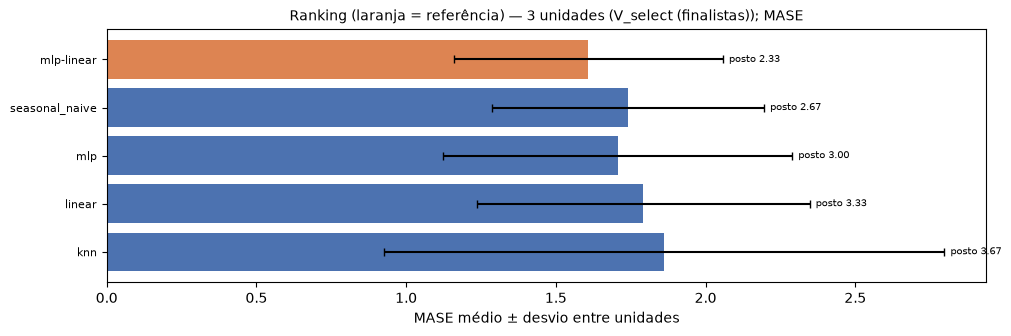

In [4]:
result.comparison.plot("leaderboard")

## 3. Temporal cross-validation

Its own folds over the development history (the sealed test is left out): 8 origins, one every 7 days, each forecasting 14 steps. All models are evaluated **on the same origins**. Options: `folds`, `step`, `fold_strategy` (`"expanding"` or `"rolling"`), `window_size` and `horizon`.

In [5]:
cv = exp.cross_validate(folds=8, step=7)
cv.splits

validação cruzada:   0%|          | 0/5 [00:00<?, ?cand/s]

validação cruzada:  20%|██        | 1/5 [00:02<00:11,  2.97s/cand]

validação cruzada:  40%|████      | 2/5 [00:04<00:05,  1.91s/cand]

validação cruzada: 100%|██████████| 5/5 [00:04<00:00,  1.74cand/s]

validação cruzada: 100%|██████████| 5/5 [00:04<00:00,  1.17cand/s]

,layer,train_start,origin,first_target,last_target,n_train,horizon
fold_id,,,,,,,
cv-0,cv,2024-01-01,2025-10-14,2025-10-15,2025-10-28,653,14
cv-1,cv,2024-01-01,2025-10-21,2025-10-22,2025-11-04,660,14
cv-2,cv,2024-01-01,2025-10-28,2025-10-29,2025-11-11,667,14
cv-3,cv,2024-01-01,2025-11-04,2025-11-05,2025-11-18,674,14
cv-4,cv,2024-01-01,2025-11-11,2025-11-12,2025-11-25,681,14
cv-5,cv,2024-01-01,2025-11-18,2025-11-19,2025-12-02,688,14
cv-6,cv,2024-01-01,2025-11-25,2025-11-26,2025-12-09,695,14
cv-7,cv,2024-01-01,2025-12-02,2025-12-03,2025-12-16,702,14


In [6]:
cv.summary

,mean,std,median,n_valid,n_units,mean_rank
model,,,,,,
mlp,1.294039,0.592503,1.221063,8,8,2.250
linear,1.391870,0.503800,1.351495,8,8,2.875
seasonal_naive,1.401389,0.399431,1.349723,8,8,3.000
mlp-linear,1.500562,0.613733,1.445802,8,8,3.250
knn,1.464256,0.645633,1.111622,8,8,3.625


In [7]:
cv.units  # MASE per origin and model

,mlp-linear,mlp,knn,seasonal_naive,linear
cv-0,0.752621,0.585961,1.106167,0.973660,0.848262
cv-1,2.097688,1.129454,1.081310,1.372579,1.376356
cv-2,1.266502,1.312672,1.793738,1.326866,1.545608
cv-3,2.512821,2.470001,2.851411,2.264966,2.407803
cv-4,0.959965,0.772428,1.117078,1.000031,0.845120
cv-5,1.789340,1.647708,0.990967,1.500052,1.639575
cv-6,1.625103,0.955602,1.030533,1.314213,1.145602
cv-7,1.000457,1.478483,1.742845,1.458741,1.326634


### Visualizations

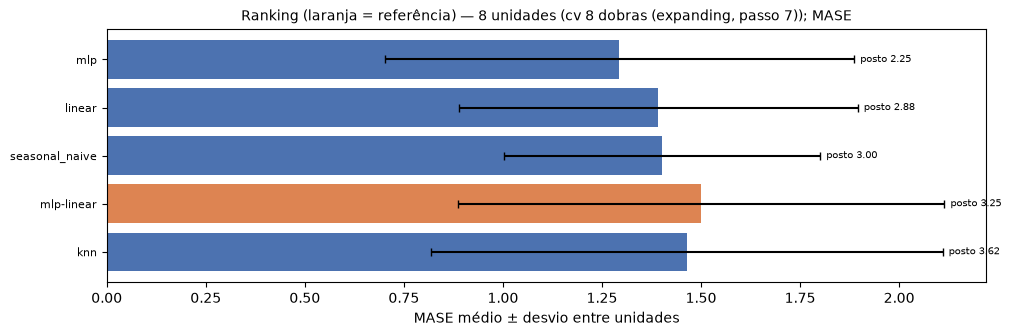

In [8]:
cv.plot("leaderboard")

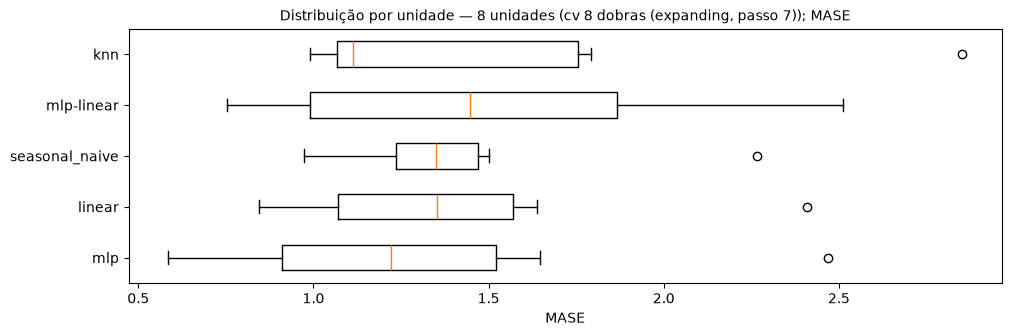

In [9]:
cv.plot("boxplot")

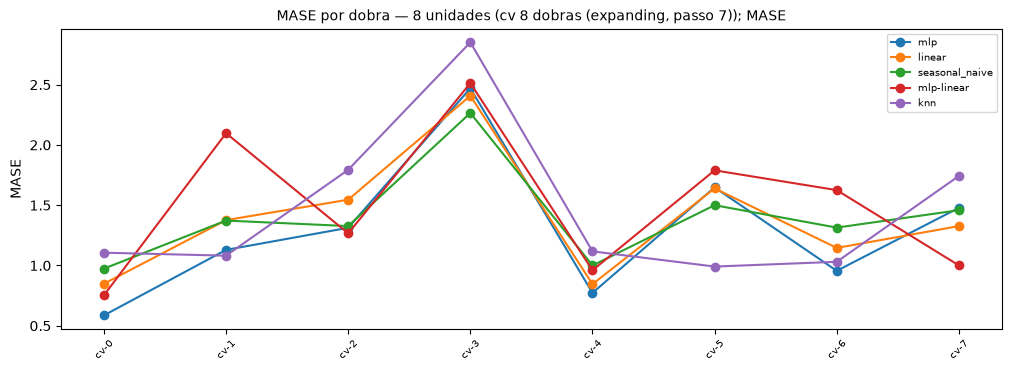

In [10]:
cv.plot("metric_by_fold")

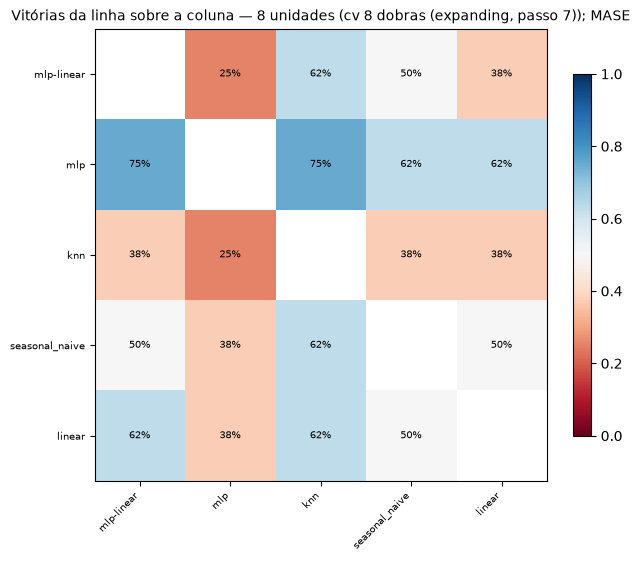

In [11]:
cv.plot("win_rate")

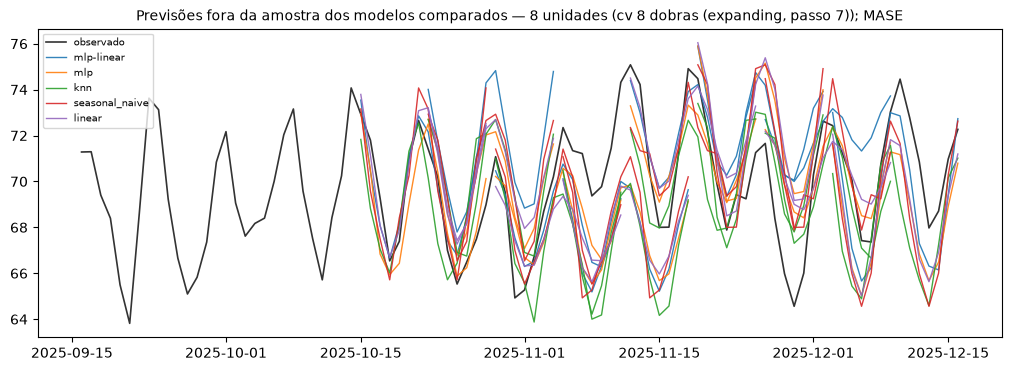

In [12]:
cv.plot("forecasts")

### Statistical tests

Each model against the reference (the champion): paired Wilcoxon and Diebold-Mariano (Newey-West variance, for origins with overlapping targets), with Holm correction. The Friedman test and the Nemenyi critical difference compare all of them at once.

With few origins the tests have little power: "no significant difference" does not mean the models are equivalent.

In [13]:
cv.tests()

,model,reference,n_units,mean_difference,median_difference,wins,wilcoxon_p,dm_statistic,dm_p,wilcoxon_p_holm,dm_p_holm
0,mlp,mlp-linear,8,0.206523,0.154146,6,0.195312,1.807143,0.113690,0.78125,0.454758
1,knn,mlp-linear,8,0.036306,-0.247851,3,0.843750,0.191534,0.853544,1.00000,0.853544
2,seasonal_naive,mlp-linear,8,0.099174,0.103894,4,0.546875,1.117511,0.300657,1.00000,0.617275
3,linear,mlp-linear,8,0.108692,0.109931,5,0.460938,1.394727,0.205758,1.00000,0.617275


In [14]:
friedman = cv.friedman()
p_value, cd = friedman["p_value"], friedman["critical_difference"]
print(f"Friedman p = {p_value:.3f}; critical difference = {cd:.2f}")
friedman["mean_ranks"].sort_values()

Friedman p = 0.509; critical difference = 2.16


mlp               2.250
linear            2.875
seasonal_naive    3.000
mlp-linear        3.250
knn               3.625
dtype: float64

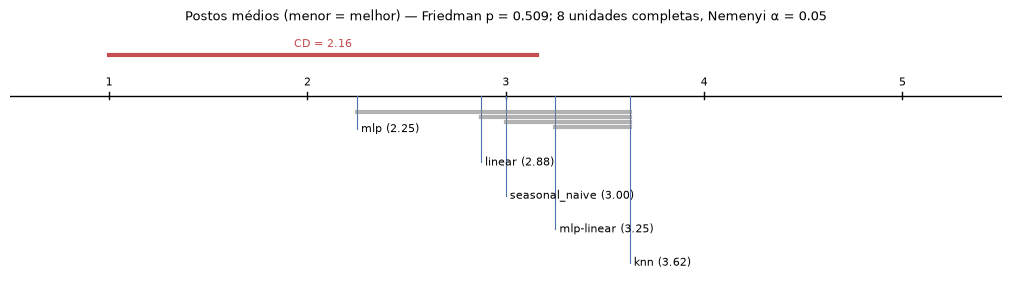

In [15]:
cv.plot("critical_difference")

## 4. Final comparison on the sealed test

Each model is finalized (refitted on the history before the test) and evaluated **only once**. It is a terminal report: changing the configuration because of it would turn the test into validation.

In [16]:
external = exp.compare_external()
external.table

teste externo:   0%|          | 0/5 [00:00<?, ?cand/s]

teste externo:  20%|██        | 1/5 [00:00<00:01,  2.42cand/s]

teste externo:  40%|████      | 2/5 [00:00<00:00,  4.05cand/s]

teste externo: 100%|██████████| 5/5 [00:00<00:00,  8.63cand/s]

,MASE,MAE,RMSE,sMAPE,ganho_MASE_vs_ref
model,,,,,
"mlp(lags=7) + linear [w=7, alpha=0.5, historical_oof_1step]",0.703257,1.101274,1.288316,0.015685,0.000000
mlp(lags=7),1.193216,1.868531,2.137723,0.026300,-0.696699
knn(lags=7),0.549934,0.861176,1.036616,0.012319,0.218018
seasonal_naive(season_length=7),0.826938,1.294953,1.560511,0.018222,-0.175868
linear(lags=7),0.660951,1.035024,1.157793,0.014720,0.060158


In [17]:
external.tests

,model,dm_statistic,dm_p,dm_p_holm
0,mlp(lags=7),-6.490174,0.000020,0.000081
1,knn(lags=7),1.611410,0.131092,0.279398
2,seasonal_naive(season_length=7),-1.812039,0.093133,0.279398
3,linear(lags=7),1.527034,0.150710,0.279398


## 5. Nested cross-validation of the procedure

In each outer fold, AutoHybTS redoes the search and the selection using only the past and is measured on the next block, alongside references. It answers the question: *does choosing automatically pay off?*

* `best_standalone` is the best base **of the inner selection** of each fold, chosen without the outer block: the fair reference for knowing whether hybridization pays off.
* `naive` and `seasonal_naive` are fixed references.
* The inner searches repeat the families of the last `compare_models` (`nested.include`), and `nested.cost` shows the work of each fold.

In [18]:
nested = exp.nested_cross_validate(outer_folds=3, budget="smoke")
print("families of the inner searches:", nested.include)
nested.folds[
    ["champion", "best_standalone", "autohybts_MASE", "best_standalone_MASE", "naive_MASE"]
]

CV aninhada:   0%|          | 0/3 [00:00<?, ?cand/s]

CV aninhada:  33%|███▎      | 1/3 [00:01<00:03,  2.00s/cand]

CV aninhada:  67%|██████▋   | 2/3 [00:03<00:01,  1.99s/cand]

CV aninhada: 100%|██████████| 3/3 [00:06<00:00,  2.16s/cand]

CV aninhada: 100%|██████████| 3/3 [00:06<00:00,  2.12s/cand]

families of the inner searches: ('standalone', 'residual')


,champion,best_standalone,autohybts_MASE,best_standalone_MASE,naive_MASE
fold_id,,,,,
cv-0,mlp(lags=7),linear(lags=7),2.373193,2.407803,1.399396
cv-1,seasonal_naive(season_length=7),seasonal_naive(season_length=7),1.500052,1.500052,3.438511
cv-2,mlp(lags=7),seasonal_naive(season_length=7),1.230691,1.458741,1.422165


In [19]:
nested.summary

,mean,std,n_folds,autohybts_wins
autohybts_MASE,1.701312,0.597250,3,NaN
best_standalone_MASE,1.788865,0.536414,3,0.666667
naive_MASE,2.086690,1.170766,3,0.666667
seasonal_naive_MASE,1.741253,0.454019,3,0.333333


In [20]:
nested.cost[["search_candidates", "search_units", "select_units", "stop_reason", "seconds_total"]]

,search_candidates,search_units,select_units,stop_reason,seconds_total
fold_id,,,,,
cv-0,9,27,15,budget_limited,1.997491
cv-1,9,27,15,budget_limited,1.985857
cv-2,9,27,15,budget_limited,2.360508
